# TP Data Visualisation — Lisibilité et accidents corporels en Île-de-France (2025)

> **Périmètre :** accidents corporels de la circulation recensés dans les huit départements franciliens en 2025.  
> **Données :** fichier officiel `caract-2025.csv`, source [data.gouv.fr](https://www.data.gouv.fr/datasets/bases-de-donnees-annuelles-des-accidents-corporels-de-la-circulation-routiere-annees-de-2005-a-2025).  
> **Référence théorique :** [GoldenViz — Lisibilité, règles 7 à 16](https://goldenviz.org/fr/readability.html).

## Partie 1 — Analyse des règles de lisibilité 7 à 16

### Règle 7 — Étiquettes et graduations lisibles
**Problème :** axes encombrés, textes trop petits ou libellés qui se chevauchent.  
**Correction :** limiter les graduations, abréger les libellés et préférer les barres horizontales lorsque les catégories portent des noms longs.  
**Application :** les catégories de luminosité sont présentées horizontalement et les valeurs sont lisibles au bout des barres.

### Règle 8 — Accessibilité des couleurs
**Problème :** teintes trop proches, contrastes insuffisants ou distinctions qui ne reposent que sur la couleur.  
**Correction :** choisir une palette contrastée, limiter le nombre de couleurs et conserver des libellés explicites.  
**Application :** une couleur principale unique est utilisée pour les barres ; les effectifs et les catégories restent compréhensibles sans la couleur.

### Règle 9 — Étiquetage direct
**Problème :** une légende éloignée force le lecteur à naviguer sans cesse entre codes couleur et données.  
**Correction :** placer les noms, valeurs ou pourcentages près des éléments correspondants.  
**Application :** effectifs et pourcentages figurent à droite de chaque barre, sans légende superflue.

### Règle 10 — Éviter le *chartjunk*
**Problème :** fonds chargés, 3D, ombres ou bordures détournent l'attention.  
**Correction :** supprimer les effets décoratifs et privilégier les repères utiles.  
**Application :** graphique plat, sans 3D, avec une grille discrète.

### Règle 11 — Trop de catégories
**Problème :** une multitude de catégories rend la comparaison difficile et peut produire des étiquettes illisibles.  
**Correction :** filtrer, agréger ou répartir les catégories entre plusieurs vues.  
**Application :** l'étude est limitée à une région et la comparaison porte sur seulement cinq modalités de luminosité.

### Règle 12 — Trier les barres catégorielles
**Problème :** dans un classement, des barres en ordre arbitraire empêchent de repérer rapidement les écarts.  
**Correction :** trier les catégories par effectif lorsque leur ordre n'est pas intrinsèquement significatif.  
**Application :** barres triées par nombre d'accidents, l'effectif le plus élevé étant affiché en haut.

### Règle 13 — Surimpression des points
**Problème :** de nombreux accidents peuvent partager des coordonnées proches et masquer la concentration réelle.  
**Correction :** utiliser la transparence, une agrégation spatiale ou une carte interactive avec zoom.  
**Application :** carte GeoJSON consultable en zoomant sur GitHub ; les points indiquent des lieux d'accident, **pas** une mesure normalisée du risque. Une agrégation par maille serait plus adaptée à une comparaison de densité fine.

### Règle 14 — Précision décimale
**Problème :** trop de décimales donnent une précision artificielle et compliquent la lecture.  
**Correction :** afficher les effectifs comme entiers et les proportions avec une décimale au maximum.  
**Application :** pourcentages arrondis à 0,1 point ; coordonnées limitées à six décimales pour l'export cartographique.

### Règle 15 — Formatage des dates
**Problème :** des dates longues et trop rapprochées sur un axe se chevauchent.  
**Correction :** utiliser un format adapté à l'échelle, par exemple `MM/AAAA` pour des mois.  
**Application :** les résultats mensuels ci-dessous sont indiqués en `MM/2025`, sans horodatage inutile.

### Règle 16 — Économie visuelle
**Problème :** multiplier les indicateurs et annotations sur une seule figure dilue le message.  
**Correction :** attribuer un objectif précis à chaque graphique et déplacer le détail complémentaire dans le texte.  
**Application :** une carte répond à la question « où ? » ; un graphique en barres répond à « dans quelles conditions de luminosité ? ».

---

## Partie 2 — Étude progressive des accidents corporels en Île-de-France

**Objectif.** Étudier les accidents corporels enregistrés en 2025 : où ont-ils eu lieu en Île-de-France, et dans quelles conditions de luminosité ? Notre analyse utilise le fichier officiel `caract-2025.csv`. Les **résultats chiffrés ne sont pas saisis à la main** : chaque tableau statistique, total ou proportion est construit par le code Python qui précède ou accompagne son interprétation.

> **Mode d'emploi :** exécuter les blocs Python **dans l'ordre**, dans une même session Python (notebook, console interactive de VS Code ou cellules `# %%` dans un fichier temporaire). Chaque bloc réutilise les variables précédentes. L'aperçu Markdown de VS Code et GitHub affiche le code, mais ne l'exécute pas. Depuis le dossier du TP, installer au besoin : `python -m pip install pandas matplotlib`.

### 1. Télécharger et explorer les données

**Source.** [Base BAAC officielle — data.gouv.fr](https://www.data.gouv.fr/datasets/bases-de-donnees-annuelles-des-accidents-corporels-de-la-circulation-routiere-annees-de-2005-a-2025). Le fichier *Caractéristiques* a été téléchargé et placé à la racine du projet sous le nom `caract-2025.csv`. Cette table décrit les caractéristiques générales et la localisation de chaque accident. Elle ne permet pas, à elle seule, de calculer le nombre de victimes ou la gravité par usager.

**Étape 1.1 — Charger le fichier.** Le séparateur est `;`. On lit initialement les colonnes comme du texte, notamment pour préserver les codes des départements (`75`, `77`, etc.).

In [3]:
%pip install matplotlib geopandas shapely ipykernel

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [4]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

source = Path("caract-2025.csv")
df = pd.read_csv(source, sep=";", dtype=str, encoding="utf-8-sig")

print("Dimensions (lignes, colonnes) :", df.shape)
print("Colonnes :", df.columns.tolist())
print(df.head(5).to_string(index=False))

Dimensions (lignes, colonnes) : (55093, 15)
Colonnes : ['Num_Acc', 'jour', 'mois', 'an', 'hrmn', 'lum', 'dep', 'com', 'agg', 'int', 'atm', 'col', 'adr', 'lat', 'long']
     Num_Acc jour mois   an  hrmn lum dep   com agg int atm col                adr         lat         long
202500000001    5   05 2025 15:35   1  02 02363   1   1   1   7                NaN 49,51853600   3,24798300
202500000002    3   05 2025 17:15   1  01 01445   1   1   1   1       Route du Fay 46,35142200   5,31882900
202500000003    5   05 2025 09:30   2  26 26148   1   1   1   7 Route de la Vallée 45,24581900   4,99457400
202500000004   24   04 2025 12:00   1  26 26188   1   3   1   4      Route du Buis 44,23943400   5,19891500
202500000005    4   05 2025 17:53   1  72 72121   1   1   1   7        la Souvelle 48,28505600  -0,08042300


**Résultat et interprétation.** Le fichier contient **55 093 lignes et 15 colonnes**. Les premières observations montrent des coordonnées stockées avec une **virgule décimale** ; leur conversion sera donc nécessaire avant la cartographie. Ces valeurs proviennent du bloc ci-dessus.

**Étape 1.2 — Vérifier le niveau d'observation et les valeurs absentes.** `Num_Acc` désigne un accident : il faut compter des identifiants uniques et non des véhicules ou des personnes.

In [5]:
print("Accidents (lignes) :", len(df))
print("Identifiants distincts :", df["Num_Acc"].nunique())
print("Identifiants répétés :", df["Num_Acc"].duplicated().sum())

colonnes_utiles = ["Num_Acc", "an", "mois", "jour", "hrmn", "dep", "lat", "long", "lum", "agg"]
print("\nValeurs manquantes par variable utile :")
print(df[colonnes_utiles].isna().sum().to_string())

Accidents (lignes) : 55093
Identifiants distincts : 55093
Identifiants répétés : 0

Valeurs manquantes par variable utile :
Num_Acc    0
an         0
mois       0
jour       0
hrmn       0
dep        0
lat        0
long       0
lum        0
agg        0


**Résultat et interprétation.** On dénombre **55 093 identifiants `Num_Acc` différents pour 55 093 lignes**, sans doublon. Les dix variables retenues ne comportent **aucune valeur manquante** au sens de Pandas. Cela ne garantit toutefois pas que les coordonnées soient numériques ou géographiquement plausibles : un contrôle supplémentaire reste indispensable.

### 2. Nettoyer et préparer les données

**Étape 2.1 — Filtrer l'Île-de-France.** La région comprend les départements de Paris, de la petite couronne et de la grande couronne. Le filtre est appliqué sur `dep` avant la conversion des coordonnées.

In [6]:
departements = {
    "75": "Paris", "77": "Seine-et-Marne", "78": "Yvelines",
    "91": "Essonne", "92": "Hauts-de-Seine",
    "93": "Seine-Saint-Denis", "94": "Val-de-Marne", "95": "Val-d'Oise"
}
idf = df.loc[df["dep"].isin(departements)].copy()

print("Accidents en France :", len(df))
print("Accidents en Île-de-France (avant nettoyage) :", len(idf))
print("Part de l'Île-de-France (%) :", round(100 * len(idf) / len(df), 1))

Accidents en France : 55093
Accidents en Île-de-France (avant nettoyage) : 14760
Part de l'Île-de-France (%) : 26.8


**Résultat.** Le filtre conserve **14 760 accidents**, soit **26,8 %** des **55 093** accidents du fichier. Il s’agit de la part dans la base et non d’une incidence rapportée à la population.

**Étape 2.2 — Convertir les coordonnées et reconstruire la date.** Le CSV utilise la virgule comme séparateur décimal. Les conversions incorrectes deviennent `NaN` ou `NaT`, afin d'être identifiées plutôt que d’être utilisées sans contrôle.

In [7]:
for col in ["lat", "long"]:
    idf[col] = pd.to_numeric(
        idf[col].str.strip().str.replace(",", ".", regex=False),
        errors="coerce"
    )

idf["date"] = pd.to_datetime(
    dict(
        year=pd.to_numeric(idf["an"], errors="coerce"),
        month=pd.to_numeric(idf["mois"], errors="coerce"),
        day=pd.to_numeric(idf["jour"], errors="coerce"),
    ),
    errors="coerce"
)

print("Latitudes non numériques :", idf["lat"].isna().sum())
print("Longitudes non numériques :", idf["long"].isna().sum())
print("Dates invalides :", idf["date"].isna().sum())

Latitudes non numériques : 0
Longitudes non numériques : 0
Dates invalides : 0


**Résultat.** Les conversions ne produisent **aucune coordonnée non numérique et aucune date invalide** pour les accidents franciliens. La validité géographique est vérifiée à l’étape suivante.

**Étape 2.3 — Contrôler les positions et dédupliquer.** Les bornes géographiques suivantes sont un contrôle de plausibilité *approximatif*, et non un découpage administratif exact. L'appartenance à la région a déjà été déterminée par le département.

In [8]:
positions_valides = (
    idf["lat"].between(48.0, 49.3)
    & idf["long"].between(1.4, 3.6)
)
dates_valides = idf["date"].notna()

accidents = (
    idf.loc[positions_valides & dates_valides]
    .drop_duplicates(subset="Num_Acc")
    .copy()
)

bilan = pd.Series({
    "Accidents IDF avant nettoyage": len(idf),
    "Positions hors bornes / manquantes": (~positions_valides).sum(),
    "Dates non valides": (~dates_valides).sum(),
    "Doublons parmi les lignes valides": idf.loc[positions_valides & dates_valides, "Num_Acc"].duplicated().sum(),
    "Accidents finalement conservés": len(accidents),
})
print(bilan.to_string())

Accidents IDF avant nettoyage         14760
Positions hors bornes / manquantes        0
Dates non valides                         0
Doublons parmi les lignes valides         0
Accidents finalement conservés        14760


**Résultat et interprétation.** Après filtrage, **14 760 accidents** appartiennent à l’Île-de-France, soit **26,8 %** du fichier national. Aucune latitude, longitude ou date francilienne n’échoue à la conversion ; aucune position ne dépasse les bornes de plausibilité retenues et aucun identifiant n’est dupliqué. Le jeu final comprend donc **14 760 accidents**, sans exclusion. Ces contrôles sont spécifiques au fichier 2025 fourni.

### 3. Construire une carte de répartition géographique

**Question :** où sont situés les accidents corporels en Île-de-France ?

**Étape 3.1 — Comparer les départements.** Avant de cartographier les points, on calcule leur distribution pour contextualiser la carte. Les effectifs et proportions proviennent ici de `groupby`, pas d'un tableau recopié.

In [9]:
par_departement = (
    accidents.groupby("dep")
    .size()
    .rename("accidents")
    .reset_index()
)
par_departement["département"] = par_departement["dep"].map(departements)
par_departement["part (%)"] = (
    100 * par_departement["accidents"] / len(accidents)
).round(1)
par_departement = par_departement.sort_values("accidents", ascending=False)

print(par_departement[["département", "accidents", "part (%)"]].to_string(index=False))
print("Total contrôlé :", par_departement["accidents"].sum())

      département  accidents  part (%)
            Paris       3681      24.9
Seine-Saint-Denis       2355      16.0
   Hauts-de-Seine       2289      15.5
     Val-de-Marne       2017      13.7
          Essonne       1338       9.1
   Seine-et-Marne       1215       8.2
         Yvelines       1005       6.8
       Val-d'Oise        860       5.8
Total contrôlé : 14760


**Résultat et interprétation.** **Paris** arrive en tête avec **3 681 accidents (24,9 %)**, suivi de la **Seine-Saint-Denis (2 355 ; 16,0 %)** et des **Hauts-de-Seine (2 289 ; 15,5 %)**. Le **Val-d’Oise (860 ; 5,8 %)** est le moins représenté. La somme des huit départements atteint bien **14 760 accidents**. Ce classement mesure les **volumes enregistrés** et non les risques relatifs : aucune donnée de circulation ou de kilomètres parcourus n’est disponible ici.

**Étape 3.2 — Produire la carte GeoJSON.** Chaque accident devient un point défini par ses coordonnées. Le format GeoJSON utilise l'ordre **longitude, latitude**. Un fichier `accidents_idf_2025.geojson` est généré à la racine du TP et peut être ouvert dans l'interface cartographique de GitHub.

In [10]:
import json

features = []
for r in accidents.itertuples(index=False):
    features.append({
        "type": "Feature",
        "geometry": {
            "type": "Point",
            "coordinates": [round(float(r.long), 6), round(float(r.lat), 6)]
        },
        "properties": {"Num_Acc": r.Num_Acc, "dep": r.dep, "lum": r.lum}
    })

geojson = {"type": "FeatureCollection", "features": features}
Path("accidents_idf_2025.geojson").write_text(
    json.dumps(geojson, ensure_ascii=False, separators=(",", ":")),
    encoding="utf-8"
)
print("Points cartographiés :", len(features))
print("Fichier créé : accidents_idf_2025.geojson")

Points cartographiés : 14760
Fichier créé : accidents_idf_2025.geojson


**Résultat.** Le fichier GeoJSON comprend **14 760 entités ponctuelles**, une par accident conservé. Il peut être exploré séparément sur GitHub, avec zoom et déplacement.

**Carte à consulter :** [ouvrir les points d'accidents sur GitHub](accidents_idf_2025.geojson). Le lien fonctionne après dépôt du fichier généré dans le même dossier ; l'affichage cartographique dépend du visualiseur GitHub. La carte reste distincte de l'aperçu `.md` (GitHub ne l'intègre pas automatiquement dans le texte).

**Étape 3.3 — Visualiser immédiatement les points avec Python.** Ce contrôle rapide affiche leur emprise géographique, sans dépendre du visualiseur GitHub. Une faible opacité limite le chevauchement visuel.

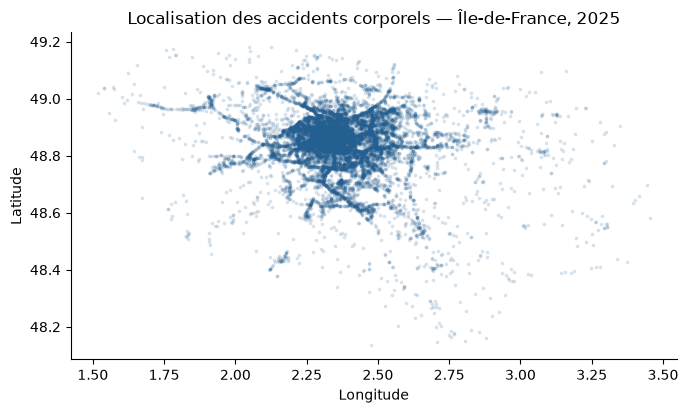

In [11]:
fig, ax = plt.subplots(figsize=(7, 7))
ax.scatter(accidents["long"], accidents["lat"], s=3, alpha=0.12, color="#245f91")
ax.set(title="Localisation des accidents corporels — Île-de-France, 2025",
       xlabel="Longitude", ylabel="Latitude")
ax.set_aspect("equal", adjustable="box")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig("carte_accidents_idf_2025.png", dpi=160, bbox_inches="tight")
plt.show()

**Résultat et interprétation.** La carte affiche **14 760 points**. Visuellement, les accidents se concentrent davantage autour de Paris et de la petite couronne, mais une carte de points ne suffit pas à comparer précisément les densités : plusieurs accidents proches peuvent se superposer. Elle renseigne sur la **localisation des événements recensés**, pas sur le risque par trajet.

### 4. Construire une seconde visualisation : conditions de luminosité

**Question :** dans quelles conditions de luminosité les accidents franciliens ont-ils été recensés ?

**Étape 4.1 — Décoder `lum` et calculer les effectifs.** La variable est catégorielle : le bon graphique est un diagramme en barres, et non une courbe continue. Les cinq modalités correspondent au dictionnaire BAAC.

In [12]:
luminosites = {
    "1": "Plein jour",
    "2": "Crépuscule / aube",
    "3": "Nuit sans éclairage public",
    "4": "Nuit, éclairage non allumé",
    "5": "Nuit, éclairage allumé",
}

bilan_lum = accidents["lum"].value_counts().reindex(luminosites.keys(), fill_value=0)
bilan_lum.index = bilan_lum.index.map(luminosites)
part_lum = (100 * bilan_lum / len(accidents)).round(1)

comparaison = pd.DataFrame({"accidents": bilan_lum, "part (%)": part_lum})
print(comparaison.to_string())
print("Total des accidents classés :", comparaison["accidents"].sum())
print("Valeurs de luminosité inconnues :", (~accidents["lum"].isin(luminosites)).sum())

                            accidents  part (%)
lum                                            
Plein jour                       9600      65.0
Crépuscule / aube                 857       5.8
Nuit sans éclairage public       1176       8.0
Nuit, éclairage non allumé        116       0.8
Nuit, éclairage allumé           3011      20.4
Total des accidents classés : 14760
Valeurs de luminosité inconnues : 0


**Résultat et interprétation.** Le **plein jour** est majoritaire avec **9 600 accidents (65,0 %)**. Viennent ensuite la **nuit avec éclairage allumé (3 011 ; 20,4 %)**, la **nuit sans éclairage public (1 176 ; 8,0 %)**, le **crépuscule / l’aube (857 ; 5,8 %)**, puis la **nuit avec éclairage non allumé (116 ; 0,8 %)**. Les cinq catégories totalisent **14 760 accidents**, sans code inconnu.

**Étape 4.2 — Tracer des barres horizontales triées.** Les libellés complets restent lisibles ; les valeurs sont inscrites directement sur les barres. Le tri réduit l'effort de comparaison.

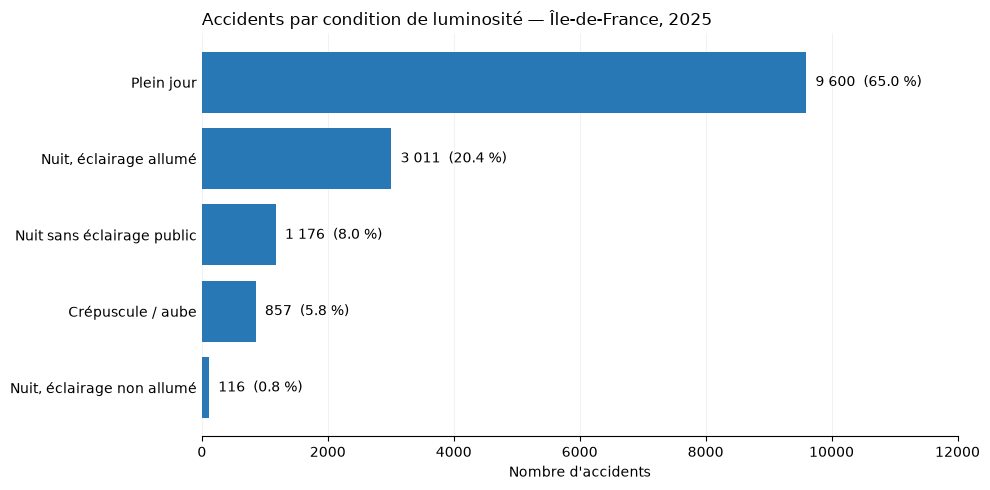

In [13]:
comparaison_ordonnee = comparaison.sort_values("accidents", ascending=True)
fig, ax = plt.subplots(figsize=(10, 5))
barres = ax.barh(comparaison_ordonnee.index, comparaison_ordonnee["accidents"],
                  color="#2878B5")

for barre, (_, ligne) in zip(barres, comparaison_ordonnee.iterrows()):
    ax.text(barre.get_width() + comparaison["accidents"].max() * 0.015,
            barre.get_y() + barre.get_height() / 2,
            f'{int(ligne["accidents"]):,}'.replace(",", " ")
            + f'  ({ligne["part (%)"]:.1f} %)',
            va="center", fontsize=10)

ax.set_xlim(0, comparaison["accidents"].max() * 1.25)
ax.set_title("Accidents par condition de luminosité — Île-de-France, 2025", loc="left")
ax.set_xlabel("Nombre d'accidents")
ax.spines[["top", "right", "left"]].set_visible(False)
ax.tick_params(axis="y", length=0)
ax.grid(axis="x", alpha=0.16)
ax.set_axisbelow(True)
plt.tight_layout()
plt.savefig("accidents_luminosite_2025.png", dpi=160, bbox_inches="tight")
plt.show()

**Étape 4.3 — Quantifier les écarts observés.** Ici encore, on calcule les chiffres au lieu de les rédiger manuellement.

In [14]:
jour = int(bilan_lum["Plein jour"])
autres = int(len(accidents) - jour)
print("Accidents de plein jour :", jour)
print("Autres conditions (y compris codes inconnus) :", autres)
print("Part de plein jour (%) :", round(100 * jour / len(accidents), 1))
print("Condition la plus fréquente :", bilan_lum.idxmax())

Accidents de plein jour : 9600
Autres conditions (y compris codes inconnus) : 5160
Part de plein jour (%) : 65.0
Condition la plus fréquente : Plein jour


**Résultat et interprétation.** On compte **9 600 accidents de plein jour** contre **5 160 sous d’autres conditions de luminosité**, soit une part de **65,0 %** pour le plein jour. Il serait incorrect d’en conclure que conduire de jour est plus dangereux : il manque la répartition du trafic selon l’heure et l’éclairage pour calculer un taux de risque.

### 5. Vérifier l'application des règles de lisibilité

| Règle GoldenViz | Application vérifiable dans notre TP |
|---|---|
| **7 — Étiquettes lisibles** | Barres horizontales, libellés écrits en entier, taille de figure adaptée. |
| **8 — Couleurs accessibles** | Une couleur principale et des valeurs textuelles : la comparaison ne dépend pas d'un code couleur. |
| **9 — Étiquetage direct** | Les effectifs et pourcentages sont affichés à côté de chaque barre. |
| **10 — Éviter le chartjunk** | Pas de 3D, d'ombres ou de décoration ; grille légère. |
| **11 — Trop de catégories** | Étude limitée à une région et aux cinq modalités de luminosité. |
| **12 — Trier les barres** | `sort_values("accidents")` produit un classement lisible. |
| **13 — Surimpression** | Taille réduite et transparence (`alpha=0.12`) sur le nuage de points géographiques, avec possibilité de zoomer dans le GeoJSON. |
| **14 — Précision décimale** | Effectifs entiers, pourcentages arrondis à une décimale. |
| **16 — Économie visuelle** | Une figure pour « où ? », une autre pour « dans quelle luminosité ? ». |

La **règle 15** (dates) peut être appliquée si l'on ajoute une analyse mensuelle. Pour montrer concrètement le formatage des dates, nous calculons rapidement les effectifs par mois ; les valeurs sont, elles aussi, issues du fichier.

In [15]:
par_mois = accidents.groupby(accidents["date"].dt.to_period("M")).size()
par_mois.index = par_mois.index.strftime("%m/%Y")
print(par_mois.rename("accidents").to_string())

date
01/2025    1176
02/2025    1013
03/2025    1275
04/2025    1313
05/2025    1365
06/2025    1482
07/2025    1155
08/2025     853
09/2025    1294
10/2025    1367
11/2025    1226
12/2025    1241


**Résultat et interprétation.** Le maximum mensuel est observé en **juin (1 482 accidents)** et le minimum en **août (853 accidents)**, soit un écart de **629 accidents**. Ces variations sont descriptives : elles ne tiennent pas compte de l’intensité du trafic ni d’éventuelles différences de déclaration.

### 6. Interprétation générale et justification des choix

Sur **55 093 accidents corporels** recensés dans le fichier national 2025, **14 760 (26,8 %)** se situent dans les huit départements franciliens. Les contrôles n’ont entraîné aucune exclusion sur ce périmètre. **Paris (3 681 accidents, 24,9 %)** concentre le plus grand effectif départemental. Les accidents survenus en **plein jour (9 600, 65,0 %)** constituent la modalité de luminosité la plus fréquente. Enfin, **juin (1 482)** est le mois comptant le plus d’accidents et **août (853)** le moins. Ces chiffres ont été calculés en exécutant les blocs ci-dessus sur `caract-2025.csv` et non estimés visuellement.

Nous avons choisi une **carte de points** parce que les accidents possèdent une latitude et une longitude ; un **diagramme en barres horizontales** parce que les conditions de luminosité sont des catégories à comparer. Des titres explicites, peu d'effets graphiques, des libellés complets et un tri rendent la lecture plus rapide.

**Limites de l'étude :** les données recensent des accidents corporels et non l'ensemble des déplacements. Ni le nombre d'habitants, ni le trafic routier, ni les kilomètres parcourus ne sont intégrés. Les comparaisons portent donc sur des **effectifs** et non sur des **taux de risque**. Le fichier Caractéristiques seul ne suffit pas non plus à étudier la gravité des blessures : il faudrait relier d'autres tables, notamment *Usagers*.

---

### Sources

- [data.gouv.fr — Base des accidents corporels de la circulation routière (2005–2025)](https://www.data.gouv.fr/datasets/bases-de-donnees-annuelles-des-accidents-corporels-de-la-circulation-routiere-annees-de-2005-a-2025)
- [GoldenViz — Lisibilité : règles 7 à 16](https://goldenviz.org/fr/readability.html)